---
# Part 1 — Data Preparation & Pipeline

## 1.1 Problem framing
| Item | Our choice |
|---|---|
| **Business problem** | A telecom company loses customers ("churn"). If we can predict who is about to leave, the company can offer them a discount or support before they go. |
| **Prediction target** | `Churn` — did the customer leave? (Yes = 1, No = 0) |
| **Task type** | Binary **classification** (two possible answers) |
| **Success metric** | **F1-score** (main) and **ROC-AUC**. We do **not** rely on accuracy because only ~27% of customers churn: a useless model that always says "No" would already be ~73% accurate. F1 rewards a model only if it actually finds the churners. |
| **Why this dataset** | 7,043 rows (> 1,000 required); mix of numeric (tenure, charges) and categorical (contract, payment method, services) features; real data problems to fix (missing values, class imbalance); good for clustering (customer segments) and fairness analysis (gender, senior citizens) in later parts; public, no privacy issues. |

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42   # fixed number so everyone gets the same results every time
print("Libraries loaded ✔")

Libraries loaded ✔


In [8]:
# Load the dataset
FILE = "Telco-Customer-Churn.csv"
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

if os.path.exists(FILE):
    df = pd.read_csv(FILE)
else:
    df = pd.read_csv(URL)

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
# Column info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [11]:
# Cleaning Data
df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
print("Missing values per column (only columns that have some):")
print(df.isna().sum()[df.isna().sum() > 0])

Missing values per column (only columns that have some):
TotalCharges    11
dtype: int64


In [12]:
# Customers with missing TotalCharges?
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


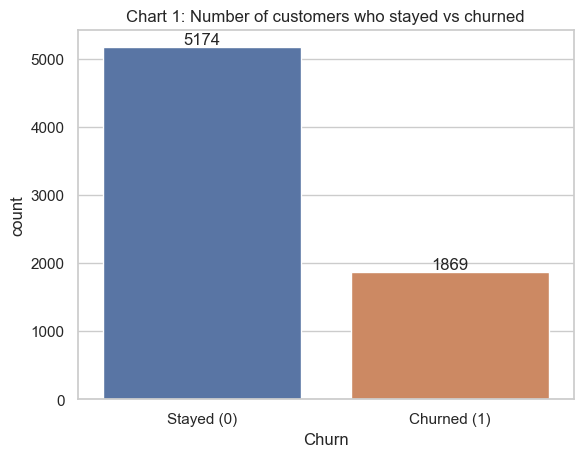

Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [13]:
# Exploratory Data Analysis (EDA
# Chart 1
ax = sns.countplot(x="Churn", data=df, hue="Churn", palette=["#4C72B0", "#DD8452"], legend=False)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Stayed (0)", "Churned (1)"])
ax.set_title("Chart 1: Number of customers who stayed vs churned")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.show()
print(df["Churn"].value_counts(normalize=True).round(3))

### Chart 2 — Churn rate by contract type

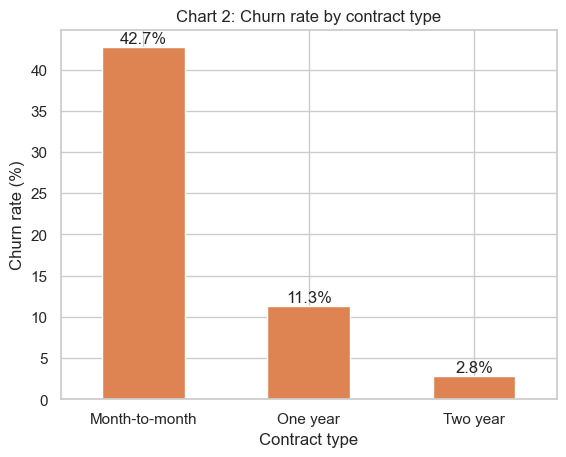

In [14]:
# Chart2
rate = df.groupby("Contract")["Churn"].mean().sort_values(ascending=False) * 100
ax = rate.plot(kind="bar", color="#DD8452")
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Contract type")
ax.set_title("Chart 2: Churn rate by contract type")
plt.xticks(rotation=0)
for i, v in enumerate(rate):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.show()

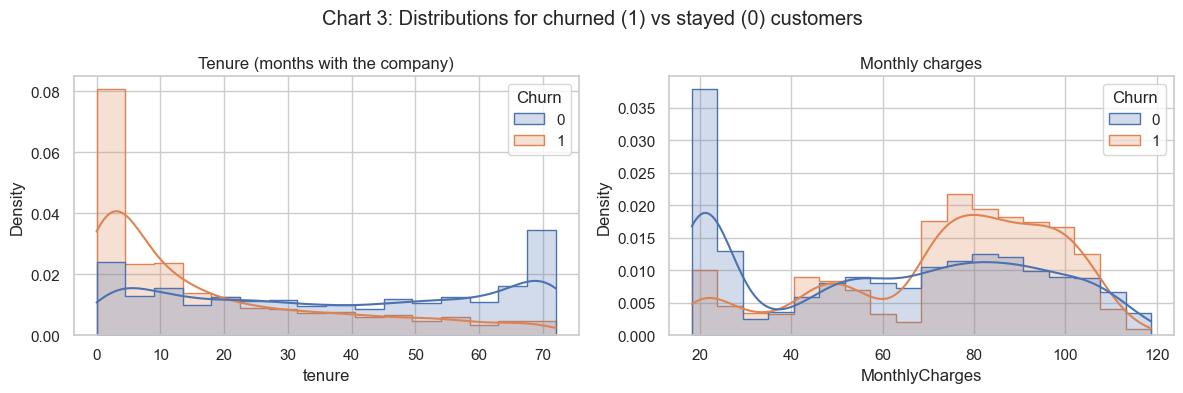

In [15]:
# Chart3
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", kde=True, element="step", stat="density",
             common_norm=False, ax=axes[0])
axes[0].set_title("Tenure (months with the company)")
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", kde=True, element="step", stat="density",
             common_norm=False, ax=axes[1])
axes[1].set_title("Monthly charges")
fig.suptitle("Chart 3: Distributions for churned (1) vs stayed (0) customers")
plt.tight_layout(); plt.show()

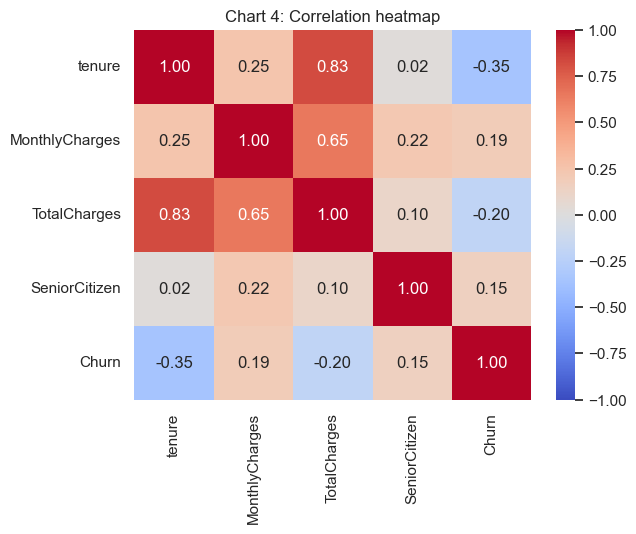

In [16]:
# Chart4
num_for_corr = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]
sns.heatmap(df[num_for_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Chart 4: Correlation heatmap")
plt.show()

tenure          -> outliers: 0
MonthlyCharges  -> outliers: 0
TotalCharges    -> outliers: 0


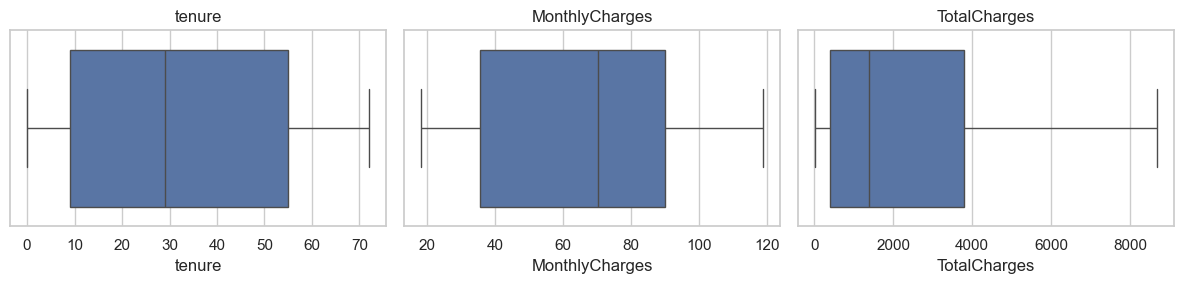

In [18]:
# Outlier Check:
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col:15s} -> outliers: {n_out}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(x=df[col], ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

In [20]:
# Data leakage testing:
X = df.drop(columns=["Churn"])   # features (inputs)
y = df["Churn"]                  # target (what we predict)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Training set:", X_train.shape, " churn rate:", round(y_train.mean(), 3))
print("Test set:    ", X_test.shape, " churn rate:", round(y_test.mean(), 3))

Training set: (5634, 19)  churn rate: 0.265
Test set:     (1409, 19)  churn rate: 0.265


In [21]:
# Feature Construction:
SERVICE_COLS = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def add_features(data):
    data = data.copy()
    data["AvgMonthlySpend"] = data["TotalCharges"] / (data["tenure"] + 1)
    data["NumServices"] = (data[SERVICE_COLS] == "Yes").sum(axis=1)
    return data

feature_maker = FunctionTransformer(add_features)

# quick test on 3 rows
add_features(X_train.head(3))[["tenure", "TotalCharges", "AvgMonthlySpend", "NumServices"]]

,tenure,TotalCharges,AvgMonthlySpend,NumServices
3738,35,1701.65,47.268056,3
3151,15,1151.55,71.971875,2
4860,13,590.35,42.167857,3


In [22]:
# PreProcessing with ColumnsTransformer:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges", "AvgMonthlySpend", "NumServices", "SeniorCitizen"]
categorical_features = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
                        "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                        "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
                        "PaperlessBilling", "PaymentMethod"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

In [23]:
# The full leakage free pipeline:
model_pipeline = Pipeline([
    ("features", feature_maker),
    ("preprocess", preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])
model_pipeline

,steps,"[('features', ...), ('preprocess', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,func,<function add...00287C194E340>
,inverse_func,None
,validate,False
,accept_sparse,False
,check_inverse,True
,feature_names_out,None
,kw_args,None


In [24]:
# Cross validation on the training set:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_validate(model_pipeline, X_train, y_train, cv=cv, scoring=["f1", "roc_auc", "accuracy"])

print(f"CV F1      : {scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}")
print(f"CV ROC-AUC : {scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}")
print(f"CV Accuracy: {scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}")

CV F1      : 0.634 ± 0.019
CV ROC-AUC : 0.849 ± 0.012
CV Accuracy: 0.756 ± 0.012


Test F1     : 0.617
Test ROC-AUC: 0.847

              precision    recall  f1-score   support

      Stayed       0.90      0.73      0.81      1035
     Churned       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409



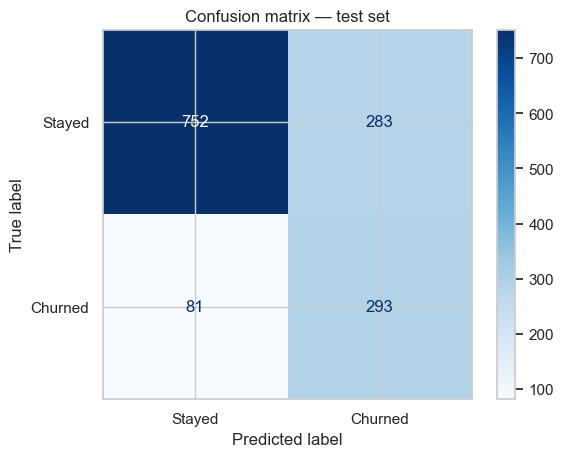

In [25]:
# Final Check on the test set:
model_pipeline.fit(X_train, y_train)

y_pred = model_pipeline.predict(X_test)
y_prob = model_pipeline.predict_proba(X_test)[:, 1]

print(f"Test F1     : {f1_score(y_test, y_pred):.3f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title("Confusion matrix — test set")
plt.show()